# 2. `src/models.py`: every model, and the two used in the submission

This file holds every model the project has tried. Only two are used in the submission, listed in `TASK_MODELS`:

| Task | Function | What it is |
|---|---|---|
| Task 2 | `task2_model` (experiment 014) | `SoftVote` of 3 tree models; flows it calls facebook or instagram are re-decided by a second `SoftVote` trained only on those two apps |
| Task 1 | `task1_cross_task` (experiment 100) | Several layers, each wrapping the previous one (see the chain at the end) |

**The building block is `SoftVote`**: a random forest, an extra-trees model and LightGBM are each trained, and their
predicted probabilities are averaged. Every larger model is a combination of `SoftVote`s with a few rules on top.

The notebook follows the file from top to bottom. Classes marked *experiment only* were tested and are not in the
submission. They are kept because the experiment logs refer to them.

> Code cells marked **from `src/models.py`** are copied from that file at commit `3b4c9c2`; the `.py` file is the one the project actually runs. Cells marked **demo** are extra examples for reading only.

In [1]:
# Setup: find the project root (the folder that holds data/official) and make src/ importable.
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "official").exists())
sys.path.insert(0, str(ROOT / "src"))
print("project root:", ROOT)

project root: <project root>


## Base learners and `SoftVote`

- `rf`, `et`, `lgbm`: the three tree models, with fixed settings (from experiment 003). `class_weight="balanced"`
  gives rare apps more weight in training.
- `MODEL_JOBS = 1`: each model uses one CPU core, because `cv.evaluate` already runs folds in parallel.
- `SoftVote`: fits the three and averages their `predict_proba`. The prediction is the app with the highest
  average probability.

In [2]:
# from src/models.py
import os

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

# Single-threaded models are fastest on 264-row folds; cv.evaluate() parallelises over folds instead.
MODEL_JOBS = int(os.environ.get("MISSION_P_MODEL_JOBS", 1))


def rf(seed, class_weight="balanced"):
    return RandomForestClassifier(n_estimators=500, class_weight=class_weight, random_state=seed, n_jobs=MODEL_JOBS)


def et(seed, class_weight="balanced"):
    return ExtraTreesClassifier(n_estimators=500, class_weight=class_weight, random_state=seed, n_jobs=MODEL_JOBS)


def lgbm(seed, class_weight="balanced"):
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=5,
                          class_weight=class_weight, random_state=seed, n_jobs=MODEL_JOBS, verbose=-1)


def resolve_class_weight(class_weight, y):
    """"balanced" / None pass through; "sqrt" = square root of the balanced weights, n / (k * n_c)."""
    if class_weight != "sqrt":
        return class_weight
    classes, counts = np.unique(y, return_counts=True)
    return {c: float(np.sqrt(len(y) / (len(classes) * n))) for c, n in zip(classes, counts)}


class SoftVote(BaseEstimator, ClassifierMixin):
    """Unweighted average of predict_proba from RF, ExtraTrees and LightGBM.

    class_weight ("balanced", None or "sqrt") is passed to every member; "balanced" is the default used by
    every champion so far.
    """

    member_factories = (rf, et, lgbm)

    def __init__(self, seed=0, class_weight="balanced"):
        self.seed = seed
        self.class_weight = class_weight

    def fit(self, X, y):
        cw = resolve_class_weight(self.class_weight, y)
        self.models_ = [f(self.seed, class_weight=cw).fit(X, y) for f in self.member_factories]
        self.classes_ = self.models_[0].classes_
        assert all((m.classes_ == self.classes_).all() for m in self.models_)
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## `PairSpecialist`: the Task 2 idea

A general model mixes up two apps that look alike. A second model trained **only on those two apps** re-decides every
flow the general model gave to either of them. Task 2 uses it for facebook vs instagram (experiment 014).

In [3]:
# from src/models.py
class PairSpecialist(BaseEstimator, ClassifierMixin):
    """Base SoftVote on `base_cols` (default: all columns); flows it predicts as one of `pair` are re-decided by a
    SoftVote trained only on the `pair` classes (experiments 013, 014)."""

    def __init__(self, base_cols=None, seed=0, spec_class_weight="balanced", spec_all_cols=True,
                 pair=("google", "youtube")):
        self.base_cols, self.seed = base_cols, seed
        self.spec_class_weight, self.spec_all_cols, self.pair = spec_class_weight, spec_all_cols, pair

    def fit(self, X, y):
        y = np.asarray(y)
        self.base_cols_ = list(X.columns) if self.base_cols is None else list(self.base_cols)
        self.base_ = SoftVote(seed=self.seed).fit(X[self.base_cols_], y)
        self.classes_ = self.base_.classes_
        m = np.isin(y, self.pair)
        self.spec_cols_ = list(X.columns) if self.spec_all_cols else self.base_cols_
        self.spec_ = SoftVote(seed=self.seed, class_weight=self.spec_class_weight).fit(X.loc[m, self.spec_cols_], y[m])
        return self

    def predict(self, X):
        pred = self.base_.predict(X[self.base_cols_])
        m = np.isin(pred, self.pair)
        if m.any():
            pred[m] = self.spec_.predict(X.loc[m, self.spec_cols_])
        return pred

## Experiment-only learners and blends (experiments 016, 017, 022)

- `logreg`, `knn`: smooth models on log-scaled features (016, not adopted).
- `rf_leaf`, `et_leaf`: tree variants with bigger leaves.
- `Blend`: a `SoftVote` over any list of members.
- `NoveltyGate`: different members for flows seen before vs new flows (017, not adopted).
- `ColumnBlend` and **`KeepClassBlend`**: average `SoftVote`s trained on different column sets. `KeepClassBlend`
  **is used in production**: it is Task 1's "whole-run expert" (022). A flow the 17-column model calls facebook stays
  facebook, because facebook's signal is in the full-flow timing.
- `MultiSpecialist`: several pair specialists in a row (015).

In [4]:
# from src/models.py
def _log_scaled(estimator):
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), estimator)


def logreg(seed, class_weight="balanced"):
    """Multinomial logistic regression on log1p + standardised features (smooth boundaries, experiment 016)."""
    from sklearn.linear_model import LogisticRegression
    return _log_scaled(LogisticRegression(C=1.0, class_weight=class_weight, max_iter=5000, random_state=seed))


def knn(seed, class_weight=None, k=7):
    """Distance-weighted kNN on log1p + standardised features; kNN has no class weights (experiment 016)."""
    from sklearn.neighbors import KNeighborsClassifier
    return _log_scaled(KNeighborsClassifier(n_neighbors=k, weights="distance"))


def rf_leaf(leaf):
    def f(seed, class_weight="balanced"):
        return RandomForestClassifier(n_estimators=500, class_weight=class_weight, min_samples_leaf=leaf,
                                      random_state=seed, n_jobs=MODEL_JOBS)
    f.__name__ = f"rf_leaf{leaf}"
    return f


def et_leaf(leaf):
    def f(seed, class_weight="balanced"):
        return ExtraTreesClassifier(n_estimators=500, class_weight=class_weight, min_samples_leaf=leaf,
                                    random_state=seed, n_jobs=MODEL_JOBS)
    f.__name__ = f"et_leaf{leaf}"
    return f


class Blend(SoftVote):
    """SoftVote over any member factories `members` (each called as f(seed, class_weight=...))."""

    def __init__(self, members=(rf, et, lgbm), seed=0, class_weight="balanced"):
        self.members = members
        super().__init__(seed=seed, class_weight=class_weight)

    @property
    def member_factories(self):
        return self.members


class NoveltyGate(BaseEstimator, ClassifierMixin):
    """Trees for flows whose exact feature vector occurs in the training data; trees + `smooth` members otherwise.

    All members are fitted once on the full training data. Seen flows get the mean proba of `trees`; unseen
    flows get the mean over `trees` + `smooth` (experiment 017). "Exact" = equal after rounding to 6 decimals.
    """

    def __init__(self, trees=(rf, et, lgbm), smooth=(logreg, knn), seed=0, class_weight="balanced"):
        self.trees, self.smooth, self.seed, self.class_weight = trees, smooth, seed, class_weight

    @staticmethod
    def _keys(X):
        return X.round(6).astype(str).agg("|".join, axis=1).values

    def fit(self, X, y):
        cw = resolve_class_weight(self.class_weight, y)
        self.trees_ = [f(self.seed, class_weight=cw).fit(X, y) for f in self.trees]
        self.smooth_ = [f(self.seed, class_weight=cw).fit(X, y) for f in self.smooth]
        self.classes_ = self.trees_[0].classes_
        assert all((m.classes_ == self.classes_).all() for m in self.trees_ + self.smooth_)
        self.seen_ = set(self._keys(X))
        return self

    def predict_proba(self, X):
        pt = [m.predict_proba(X) for m in self.trees_]
        p_seen = np.mean(pt, axis=0)
        p_new = np.mean(pt + [m.predict_proba(X) for m in self.smooth_], axis=0)
        seen = np.isin(self._keys(X), list(self.seen_))
        return np.where(seen[:, None], p_seen, p_new)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class ColumnBlend(BaseEstimator, ClassifierMixin):
    """Average predict_proba of SoftVotes fitted on different column subsets (experiment 022).

    `subsets` is a tuple of column-name tuples; "all" means every column given to fit.
    """

    def __init__(self, subsets=("all",), seed=0):
        self.subsets, self.seed = subsets, seed

    def fit(self, X, y):
        self.cols_ = [list(X.columns) if c == "all" else list(c) for c in self.subsets]
        self.models_ = [SoftVote(seed=self.seed).fit(X[c], y) for c in self.cols_]
        self.classes_ = self.models_[0].classes_
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X[c]) for m, c in zip(self.models_, self.cols_)], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class KeepClassBlend(ColumnBlend):
    """ColumnBlend, but wherever the first subset's model alone predicts `keep`, that label stands (experiment 022).

    Used to add prefix-5 columns to Task 1 without diluting Facebook, whose signal is in the full-flow timing.
    """

    def __init__(self, subsets=("all",), seed=0, keep="facebook"):
        super().__init__(subsets=subsets, seed=seed)
        self.keep = keep

    def predict(self, X):
        pred = super().predict(X)
        first = self.models_[0].predict(X[self.cols_[0]])
        pred[first == self.keep] = self.keep
        return pred


class MultiSpecialist(BaseEstimator, ClassifierMixin):
    """Base SoftVote on `base_cols`, then one pair specialist per entry of `specialists`.

    Each entry is (pair, spec_cols, class_weight): flows the base predicts as one of `pair` are re-decided by a
    SoftVote trained only on that pair, on `spec_cols` ("base" = base_cols, "all" = every column given to fit).
    Pairs must be disjoint. With one ("facebook", "instagram") entry it equals task2_model (experiment 015).
    """

    def __init__(self, base_cols=None, specialists=(), seed=0, base_members=None, base_factory=None):
        self.base_cols, self.specialists, self.seed, self.base_members = base_cols, specialists, seed, base_members
        self.base_factory = base_factory

    def fit(self, X, y):
        y = np.asarray(y)
        self.base_cols_ = list(X.columns) if self.base_cols is None else list(self.base_cols)
        if self.base_factory is not None:
            base = self.base_factory(self.seed)
        else:
            base = SoftVote(seed=self.seed) if self.base_members is None else Blend(self.base_members, seed=self.seed)
        self.base_ = base.fit(X[self.base_cols_], y)
        self.classes_ = self.base_.classes_
        self.specs_ = []
        for pair, cols, cw in self.specialists:
            cols = self.base_cols_ if cols == "base" else list(X.columns) if cols == "all" else list(cols)
            m = np.isin(y, pair)
            self.specs_.append((pair, cols, SoftVote(seed=self.seed, class_weight=cw).fit(X.loc[m, cols], y[m])))
        return self

    def predict(self, X):
        pred = self.base_.predict(X[self.base_cols_])
        for pair, cols, model in self.specs_:
            m = np.isin(pred, pair)
            if m.any():
                pred[m] = model.predict(X.loc[m, cols])
        return pred

## The production entry points

These short functions name the models. Each Task 1 version wraps the one before it. `TASK_MODELS` at the end is
what `make_submission.py` reads.

| Function | Experiment | Adds |
|---|---|---|
| `task1_model` | 022 | Whole-run expert: blend of 17-column and 34-column `SoftVote`s, facebook calls kept |
| `task1_two_clerks` | 028 | Averages it with an "opening expert" on the 12 `p5_` columns |
| `task1_meta_gate` | 034 | A Meta (facebook + instagram) vs rest gate that can move flows into Meta |
| `task1_pair_verifiers` | 084 | Re-checks instagram calls (vs google) and x calls (vs google) |
| `task1_bundle` | 089 | A third expert on the rest-of-flow columns, plus two rules |
| **`task1_cross_task`** | **100** | **Current**: an inner copy of the Task 2 model; its instagram calls rescue flows into facebook |

The classes they return are defined further down, which is fine in Python: a name is looked up only when the
function is called.

In [5]:
# from src/models.py
def task2_model(seed):
    """Task 2 champion (experiment 014): balanced SoftVote + unweighted facebook/instagram specialist."""
    return PairSpecialist(seed=seed, spec_class_weight=None, spec_all_cols=False, pair=("facebook", "instagram"))


T1_COLS = ("duration", "transport", "packet_count_up", "packet_count_down", "bytes_up", "bytes_down",
           "mean_pkt_size_up", "mean_pkt_size_down", "std_pkt_size_up", "std_pkt_size_down", "mean_iat", "std_iat",
           "min_iat", "max_iat", "burst_count", "up_down_packet_ratio", "up_down_byte_ratio")


def task1_model(seed):
    """Task 1 champion (experiment 022): mean proba of a SoftVote on the 17 Task 1 columns and a SoftVote on those
    + the 17 prefix-5 columns; flows the 17-column model calls facebook stay facebook."""
    return KeepClassBlend((T1_COLS, "all"), seed=seed, keep="facebook")


def task1_two_clerks(seed):
    """Task 1 production model since 2026-10-01 (experiment 028, adopted as a deliberate exception): whole-run expert
    (task1_model) and opening expert (SoftVote on the 12 prefix-5 columns without timing) averaged; whole-run expert
    decides whenever either side says facebook/instagram; facebook calls of the 17-column SoftVote kept.
    Defined lazily because TwoClerks is declared further down this module."""
    return TwoClerks(seed=seed, mode="avg_meta_whole")


def task1_meta_gate(seed):
    """Task 1 production model since 2026-10-01 (experiment 034, adopted as a deliberate, decision-theoretic exception):
    the two-clerks model plus a Meta-vs-rest gate that can move flows from outside Meta into Meta (facebook vs instagram by
    the whole-run expert). Defined lazily because MetaGate is declared further down this module."""
    return MetaGate(seed=seed)


def task1_pair_verifiers(seed):
    """Task 1 production model since 2026-10-09 (experiment 084, arm ALL; rule v2 BETTER on cv_seeds 2026-2030): the 034
    Meta-gate model, with its instagram calls re-decided by a google-vs-instagram verifier (083) and its x calls by a
    google-vs-x verifier. Defined lazily because PairVerifiers is declared further down this module."""
    return PairVerifiers(seed=seed)


def task1_bundle(seed):
    """Task 1 production model since 2026-10-10 (experiment 089, arm B1; rule v2 BETTER on the never-used cv_seeds
    2031-2035, mean +0.0141): 084 ALL plus the 065 rest-of-flow expert, the 087 instagram rule and the 036 scoped H1
    override. Takes the 34 production columns and derives the 11 rest-of-flow columns itself. Defined lazily because
    Task1Bundle is declared further down this module."""
    return Task1Bundle(seed=seed)


def task1_cross_task(seed):
    """Task 1 production model since 2026-10-12 (experiment 100, arm FB; adopted as a deliberate exception, user decision):
    the 089 bundle plus an inner copy of the Task 2 production model (014) on the Task 2 file's 12 no-timing columns; a flow
    the inner model calls instagram while the bundle calls it non-Meta becomes facebook. Defined lazily because
    CrossTaskMetaRescue is declared further down this module."""
    return CrossTaskMetaRescue(seed=seed)


# Model used by the submission for each task.
TASK_MODELS = {"task1_static": task1_cross_task, "task2_realtime_prefix5": task2_model}

## Experiment-only models (experiments 024 to 033)

None of these is in the submission:

- `catboost`, `SoftVote4`: CatBoost as a fourth member.
- `tabpfn`, `tabpfn_ft`, `PlusMember`: a pretrained model (TabPFN). It is parked because the project uses no outside
  pretrained models.
- `SelfTrain`: adds confident test-time predictions as extra training rows (025).
- `concept_flags`, `ConceptAugment`: hand-made behaviour flags or clusters as extra columns (029).
- `BehaviourNB`, `ProbaMix`, `_decide`, `_base_proba`, `_hybrid`, `BehaviourHybrid`: a naive-Bayes "probability of
  behaviour" correction (032, 033).

In [6]:
# from src/models.py
def catboost(seed, class_weight="balanced", cat_transport=False, balanced=None):
    """CatBoost defaults (1000 iterations, depth 6), single-threaded. cat_transport treats `transport` as categorical.

    `balanced` is the 009 spelling (True/False) and overrides class_weight when given.
    """
    from catboost import CatBoostClassifier
    if balanced is not None:
        class_weight = "balanced" if balanced else None
    weights = {"auto_class_weights": "Balanced"} if class_weight == "balanced" else \
        {"class_weights": class_weight} if isinstance(class_weight, dict) else {}
    return CatBoostClassifier(random_seed=seed, thread_count=MODEL_JOBS, verbose=0, allow_writing_files=False,
                              cat_features=["transport"] if cat_transport else None, **weights)


class SoftVote4(SoftVote):
    """SoftVote with CatBoost as a fourth member."""
    member_factories = (rf, et, lgbm, catboost)


def tabpfn(seed, class_weight=None):
    """TabPFN v2 classifier (pretrained on synthetic data; ungated weights, run locally on CPU). Experiment 024.

    Outside pretrained model: must be disclosed in the technical report. class_weight is ignored.
    """
    import torch
    from tabpfn import TabPFNClassifier
    from tabpfn.constants import ModelVersion
    torch.set_num_threads(MODEL_JOBS)
    return TabPFNClassifier.create_default_for_version(ModelVersion.V2, device="cpu", random_state=seed)


class PlusMember(BaseEstimator, ClassifierMixin):
    """`base_factory(seed)` + one extra member on all columns; probabilities averaged with weight `w` for the extra
    member; flows the base's first sub-model calls `keep` stay `keep` (experiment 024)."""

    def __init__(self, base_factory=None, extra_factory=None, seed=0, w=1 / 3, keep="facebook"):
        self.base_factory, self.extra_factory, self.seed, self.w, self.keep = base_factory, extra_factory, seed, w, keep

    def fit(self, X, y):
        self.base_ = self.base_factory(self.seed).fit(X, y)
        self.extra_ = self.extra_factory(self.seed).fit(X, y)
        self.classes_ = self.base_.classes_
        extra_classes = getattr(self.extra_, "classes_", None)
        if extra_classes is None:  # FinetunedTabPFNClassifier keeps them on its inference classifier
            extra_classes = self.extra_.finetuned_inference_classifier_.classes_
        assert (np.asarray(extra_classes) == self.classes_).all()
        return self

    def predict(self, X):
        p = (1 - self.w) * self.base_.predict_proba(X) + self.w * self.extra_.predict_proba(X)
        pred = self.classes_[p.argmax(axis=1)]
        first = self.base_.models_[0].predict(X[self.base_.cols_[0]])
        pred[first == self.keep] = self.keep
        return pred


class SelfTrain(BaseEstimator, ClassifierMixin):
    """One round of self-training at prediction time (experiment 025).

    fit() stores the labelled data and fits `base_factory(seed)`. predict(X): the unlabelled pool is X plus
    `extra_pool` (feature rows only, never labels); pool rows whose confidence ≥ `threshold` and whose predicted
    class is not in `exclude` are added with their predicted label; the base is refitted once and predicts X.
    Confidence = max predict_proba of the model, or of its `base_` sub-model when it has no predict_proba.
    """

    def __init__(self, base_factory=None, seed=0, threshold=0.9, exclude=("facebook", "instagram"), extra_pool=None):
        self.base_factory, self.seed, self.threshold = base_factory, seed, threshold
        self.exclude, self.extra_pool = exclude, extra_pool

    @staticmethod
    def _proba(model, X):
        m = model if hasattr(model, "predict_proba") else model.base_
        cols = getattr(model, "base_cols_", None)
        return m.predict_proba(X[cols] if cols is not None and m is not model else X)

    def fit(self, X, y):
        self.X_, self.y_ = X.reset_index(drop=True), np.asarray(y)
        self.model_ = self.base_factory(self.seed).fit(self.X_, self.y_)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        pool = X if self.extra_pool is None else pd.concat([X, self.extra_pool[X.columns]], ignore_index=True)
        pool = pool.reset_index(drop=True)
        conf = self._proba(self.model_, pool).max(axis=1)
        pred = self.model_.predict(pool)
        keep = (conf >= self.threshold) & ~np.isin(pred, self.exclude)
        self.n_pseudo_ = int(keep.sum())
        X2 = pd.concat([self.X_, pool[keep]], ignore_index=True)
        y2 = np.concatenate([self.y_, pred[keep]])
        return self.base_factory(self.seed).fit(X2, y2).predict(X.reset_index(drop=True))


def tabpfn_ft(seed, class_weight=None):
    """TabPFN v2 fine-tuned on the training fold (experiment 026), local CPU, package defaults fixed in advance:
    30 epochs max, lr 1e-5, early stopping on an internal 10% split. Outside pretrained model: disclose."""
    import torch
    from tabpfn.constants import ModelVersion
    from tabpfn.finetuning.finetuned_classifier import FinetunedTabPFNClassifier
    torch.set_num_threads(MODEL_JOBS)
    return FinetunedTabPFNClassifier(device="cpu", model_version=ModelVersion.V2, random_state=seed)

## `TwoClerks` (experiment 028, in production)

Two experts look at the same Task 1 flow:

- the **whole-run** expert (`task1_model`) uses all 34 columns;
- the **opening** expert uses only the 12 `p5_` columns without timing (the first 5 packets).

Their probabilities are averaged (`mode="avg_meta_whole"`). Facebook and instagram share very similar openings, so
whenever either side says facebook or instagram, the whole-run expert decides.

In [7]:
# from src/models.py
class TwoClerks(BaseEstimator, ClassifierMixin):
    """Task 1 as two experts (experiment 028): the whole-run model (`task1_model`) and an opening expert (SoftVote on
    the prefix-5 columns without timing, i.e. the Task 2 recipe on the Task 2 file's columns of the same flow).
    mode "avg": mean of the two probability vectors; "confident": per flow, the expert with the higher max proba;
    "avg_meta_whole": "avg", but whenever either the vote or the whole-run model says facebook/instagram, the
    whole-run model's label is used (the siblings share an opening, 013 Instagram + 2 Facebook flows).
    Flows the 17-column Task 1 SoftVote alone calls facebook stay facebook (022 rule)."""

    OPEN_COLS = ("p5_transport", "p5_packet_count_up", "p5_packet_count_down", "p5_bytes_up", "p5_bytes_down",
                 "p5_mean_pkt_size_up", "p5_mean_pkt_size_down", "p5_std_pkt_size_up", "p5_std_pkt_size_down",
                 "p5_burst_count", "p5_up_down_packet_ratio", "p5_up_down_byte_ratio")

    def __init__(self, seed=0, mode="avg"):
        self.seed, self.mode = seed, mode

    def fit(self, X, y):
        self.whole_ = task1_model(self.seed).fit(X, y)
        self.opening_ = SoftVote(seed=self.seed).fit(X[list(self.OPEN_COLS)], y)
        self.classes_ = self.whole_.classes_
        assert (self.opening_.classes_ == self.classes_).all()
        return self

    def predict(self, X):
        pw = self.whole_.predict_proba(X)
        po = self.opening_.predict_proba(X[list(self.OPEN_COLS)])
        if self.mode == "avg":
            p = (pw + po) / 2
        elif self.mode.startswith("avg"):
            p = (pw + po) / 2
        else:
            p = np.where((pw.max(axis=1) >= po.max(axis=1))[:, None], pw, po)
        pred = self.classes_[p.argmax(axis=1)]
        if self.mode.endswith("_meta_whole"):  # siblings share an opening; the whole run separates them (028)
            whole = self.whole_.predict(X)
            meta = np.isin(pred, ("facebook", "instagram")) | np.isin(whole, ("facebook", "instagram"))
            pred[meta] = whole[meta]
        first = self.whole_.models_[0].predict(X[self.whole_.cols_[0]])
        pred[first == "facebook"] = "facebook"
        return pred

Back to the experiment-only behaviour models (029 to 033), which sit between `TwoClerks` and `MetaGate` in the file:

In [8]:
# from src/models.py
def concept_flags(X):
    """Experiment 029, V1: behaviour concepts from first principles, thresholds fixed before running (never tuned).
    Uses the 17 Task 1 columns of the full flow."""
    n = X.packet_count_up + X.packet_count_down
    rate_down = np.where(X.duration > 0, X.bytes_down / np.where(X.duration > 0, X.duration, 1), 0.0)
    return pd.DataFrame({
        "c_keepalive": ((X.duration > 60) & (X.mean_iat > 2) & (X.mean_pkt_size_down < 200) & (X.mean_pkt_size_up < 300)),
        "c_quick": ((X.duration < 2) & (n <= 40)),
        "c_bulk_download": ((X.bytes_down > 100_000) & (X.up_down_byte_ratio < 0.2)),
        "c_upload_heavy": (X.up_down_byte_ratio > 1.2),
        "c_streaming": ((X.duration > 30) & (rate_down > 50_000)),
        "c_bursty": (X.burst_count >= 10),
    }, index=X.index).astype(int)


class ConceptAugment(BaseEstimator, ClassifierMixin):
    """Experiment 029: add behaviour concepts to the Task 1 input, then fit `base_factory` (task1_model).

    kind "rules": concept_flags on the 17 Task 1 columns.
    kind "clusters": KMeans(k) fitted without labels on the training flows' log1p + standardised 17 Task 1 columns
    (inside fit, so inside each CV fold); features = distance to each of the k centroids (a learned "kind of run").
    """

    def __init__(self, base_factory=None, seed=0, kind="rules", k=8):
        self.base_factory, self.seed, self.kind, self.k = base_factory, seed, kind, k

    def _augment(self, X):
        T = X[list(T1_COLS)]
        if self.kind == "rules":
            C = concept_flags(T)
        else:
            Z = (np.log1p(T.clip(lower=0)) - self.mu_) / self.sd_
            C = pd.DataFrame(self.km_.transform(Z.values), index=X.index,
                             columns=[f"c_dist{i}" for i in range(self.k)])
        return pd.concat([X, C], axis=1)

    def fit(self, X, y):
        if self.kind == "clusters":
            from sklearn.cluster import KMeans
            L = np.log1p(X[list(T1_COLS)].clip(lower=0))
            self.mu_, self.sd_ = L.mean(), L.std().replace(0, 1)
            self.km_ = KMeans(n_clusters=self.k, n_init=10, random_state=self.seed).fit(((L - self.mu_) / self.sd_).values)
        self.model_ = self.base_factory(self.seed).fit(self._augment(X), y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(self._augment(X))


class BehaviourNB(BaseEstimator, ClassifierMixin):
    """Experiment 032: "probabilities of behaviour". Each feature is cut into `n_bins` quantile levels (cut points fitted
    on the training data only); a categorical naive Bayes learns P(level | app) with Laplace smoothing `alpha`; equal
    class priors (fit_prior False) so small apps are not drowned out. Prefix-5 timing columns (p5_duration, p5_*iat) are
    ignored when present (experiment 007: opening timing is noise). Settings fixed before running."""

    P5_TIMING = ("p5_duration", "p5_mean_iat", "p5_std_iat", "p5_min_iat", "p5_max_iat")

    def __init__(self, seed=0, class_weight=None, n_bins=5, alpha=1.0):
        self.seed, self.class_weight, self.n_bins, self.alpha = seed, class_weight, n_bins, alpha

    def fit(self, X, y):
        from sklearn.naive_bayes import CategoricalNB
        from sklearn.preprocessing import KBinsDiscretizer
        self.cols_ = [c for c in X.columns if c not in self.P5_TIMING]
        self.kb_ = KBinsDiscretizer(n_bins=self.n_bins, encode="ordinal", strategy="quantile",
                                    quantile_method="averaged_inverted_cdf").fit(X[self.cols_].values.astype(float))
        self.nb_ = CategoricalNB(alpha=self.alpha, fit_prior=False,
                                 min_categories=self.n_bins).fit(self.kb_.transform(X[self.cols_].values.astype(float)), y)
        self.classes_ = self.nb_.classes_
        return self

    def predict_proba(self, X):
        return self.nb_.predict_proba(self.kb_.transform(X[self.cols_].values.astype(float)))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class ProbaMix(BaseEstimator, ClassifierMixin):
    """Weighted mean of predict_proba of `factories` (each f(seed)); used to add a member to the Task 2 base (032)."""

    def __init__(self, factories=(), weights=(), seed=0):
        self.factories, self.weights, self.seed = factories, weights, seed

    def fit(self, X, y):
        self.models_ = [f(self.seed).fit(X, y) for f in self.factories]
        self.classes_ = self.models_[0].classes_
        assert all((m.classes_ == self.classes_).all() for m in self.models_)
        return self

    def predict_proba(self, X):
        w = np.asarray(self.weights, float) / np.sum(self.weights)
        return np.tensordot(w, np.array([m.predict_proba(X) for m in self.models_]), axes=1)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def _decide(task, model, X, p):
    """Final production decision from a probability vector `p` over model.classes_ (experiment 033).
    Task 1 (KeepClassBlend): argmax, then rows the 17-column SoftVote calls facebook stay facebook.
    Task 2 (PairSpecialist): argmax; rows labelled facebook/instagram are re-decided by the facebook/instagram stage."""
    cls = np.asarray(model.classes_)
    pred = cls[p.argmax(axis=1)]
    if task == "task1_static":
        first = model.models_[0].predict(X[model.cols_[0]])
        pred[first == "facebook"] = "facebook"
    else:
        m = np.isin(pred, model.pair)
        if m.any():
            pred[m] = model.spec_.predict(X.loc[m, model.spec_cols_])
    return pred


def _base_proba(task, model, X):
    return model.predict_proba(X) if task == "task1_static" else model.base_.predict_proba(X[model.base_cols_])


def _hybrid(p, q, lam, tau):
    """Gated tempered Bayesian update: rows whose top-two margin of p is < tau get p * q**lam (renormalised)."""
    if lam == 0:
        return p
    s = np.sort(p, axis=1)
    gate = (s[:, -1] - s[:, -2]) < tau
    r = p * np.clip(q, 1e-12, None) ** lam
    r /= r.sum(axis=1, keepdims=True)
    return np.where(gate[:, None], r, p)


class BehaviourHybrid(BaseEstimator, ClassifierMixin):
    """Experiment 033: production pipeline + BehaviourNB as a gated, tempered Bayesian correction.

    (lam, tau) are chosen inside fit by an inner stratified CV on the training data only, from a fixed grid that includes
    lam = 0 (no change); ties prefer the smallest lam. The official macro F1 is the inner selection metric."""

    LAMS, TAUS = (0.0, 0.25, 0.5, 1.0), (0.1, 0.2, 0.3)

    def __init__(self, task="task1_static", seed=0, inner_folds=3):
        self.task, self.seed, self.inner_folds = task, seed, inner_folds

    def _base(self, seed):
        return TASK_MODELS[self.task](seed)

    def fit(self, X, y):
        from sklearn.model_selection import StratifiedKFold
        from evaluation_metric import macro_f1
        y = np.asarray(y)
        inner = []
        for tr, va in StratifiedKFold(self.inner_folds, shuffle=True, random_state=self.seed).split(X, y):
            m = self._base(self.seed).fit(X.iloc[tr], y[tr])
            nb = BehaviourNB(seed=self.seed).fit(X.iloc[tr], y[tr])
            Xv = X.iloc[va]
            inner.append((m, Xv, y[va], _base_proba(self.task, m, Xv), nb.predict_proba(Xv)))
        best, self.grid_ = None, []
        for lam in self.LAMS:
            for tau in (self.TAUS if lam > 0 else (0.0,)):
                yt, yp = [], []
                for m, Xv, yv, p, q in inner:
                    yt += list(yv)
                    yp += list(_decide(self.task, m, Xv, _hybrid(p, q, lam, tau)))
                score = macro_f1(yt, yp)
                self.grid_.append((lam, tau, score))
                if best is None or score > best[2] + 1e-12:
                    best = (lam, tau, score)
        self.lam_, self.tau_ = best[0], best[1]
        self.model_ = self._base(self.seed).fit(X, y)
        self.nb_ = BehaviourNB(seed=self.seed).fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        p = _base_proba(self.task, self.model_, X)
        q = self.nb_.predict_proba(X)
        return _decide(self.task, self.model_, X, _hybrid(p, q, self.lam_, self.tau_))

## `MetaGate` (experiment 034, in production)

A separate `SoftVote` (the gate) learns only "Meta (facebook or instagram) or not". Its Meta probability `g` reweights
the two-clerks probabilities: Meta apps share `g` and the other four share `1 - g`. If the reweighted winner is a
Meta app, the whole-run expert picks facebook vs instagram. This lets flows that the two clerks sent elsewhere be
moved into Meta.

In [9]:
# from src/models.py
class MetaGate(BaseEstimator, ClassifierMixin):
    """Experiment 034: hierarchical "is it Meta?" step on top of the Task 1 two-clerks model.

    A balanced SoftVote gate learns Meta (facebook + instagram) vs the rest from all Task 1 columns. The two-clerks average
    probabilities p are re-weighted to agree with the gate: p'(c) = g * p(c)/p(Meta) for Meta classes and
    (1 - g) * p(c)/p(rest) otherwise. If argmax p' is a Meta class, the whole-run expert chooses facebook vs instagram.
    Then the two-clerks rules apply unchanged: whole-run label when it says facebook/instagram; facebook calls of the
    17-column SoftVote kept. Settings fixed before running.
    mode "rescue" (034b, designed after seeing 034): keep the two-clerks decision; only rows it labels outside Meta while
    the gate-weighted argmax is Meta are moved into Meta (facebook vs instagram by the whole-run expert)."""

    META = ("facebook", "instagram")

    def __init__(self, seed=0, mode="full"):
        self.seed, self.mode = seed, mode

    def fit(self, X, y):
        y = np.asarray(y)
        self.clerks_ = TwoClerks(seed=self.seed, mode="avg_meta_whole").fit(X, y)
        self.gate_ = SoftVote(seed=self.seed).fit(X, np.where(np.isin(y, self.META), "meta", "rest"))
        self.classes_ = self.clerks_.classes_
        return self

    def predict(self, X):
        c = self.clerks_
        cls = np.asarray(self.classes_)
        pw = c.whole_.predict_proba(X)
        po = c.opening_.predict_proba(X[list(c.OPEN_COLS)])
        p = (pw + po) / 2
        g = self.gate_.predict_proba(X)[:, list(self.gate_.classes_).index("meta")]
        meta = np.isin(cls, self.META)
        pm = p[:, meta].sum(axis=1, keepdims=True)
        pr = p[:, ~meta].sum(axis=1, keepdims=True)
        q = np.where(meta, g[:, None] * p / np.clip(pm, 1e-12, None), (1 - g[:, None]) * p / np.clip(pr, 1e-12, None))
        if self.mode == "rescue":
            # 034b: start from the unchanged two-clerks decision; only flows it sends outside Meta can be moved into Meta
            pred = np.asarray(c.predict(X)).copy()
            gate_meta = np.isin(cls[q.argmax(axis=1)], self.META) & ~np.isin(pred, self.META)
            fb, ig = list(cls).index("facebook"), list(cls).index("instagram")
            pred[gate_meta] = np.where(pw[gate_meta, fb] >= pw[gate_meta, ig], "facebook", "instagram")
            return pred
        pred = cls[q.argmax(axis=1)]
        in_meta = np.isin(pred, self.META)
        fb, ig = list(cls).index("facebook"), list(cls).index("instagram")
        pred[in_meta] = np.where(pw[in_meta, fb] >= pw[in_meta, ig], "facebook", "instagram")
        whole = c.whole_.predict(X)
        w_meta = np.isin(whole, self.META)
        pred[w_meta] = whole[w_meta]
        first = c.whole_.models_[0].predict(X[c.whole_.cols_[0]])
        pred[first == "facebook"] = "facebook"
        return pred

## `ScopedH1` (036) and `PairVerifiers` (083/084), both in production

- `ScopedH1`: if a flow's exact opening (12 `p5_` columns) appears in training with a single non-Meta app, and the
  model also predicts a non-Meta app, use the app seen in training.
- `PairVerifiers`: every flow the base model calls **instagram** is re-decided by a google-vs-instagram model, and
  every **x** call by a google-vs-x model. Both models are trained only on the rows of those two apps.

In [10]:
# from src/models.py
class ScopedH1(BaseEstimator, ClassifierMixin):
    """Experiment 036: production Task 1 model + a scoped exact-opening override. If a flow's exact opening (the 12 prefix-5
    columns without timing) occurs in the training data with a single label L, and neither the model's prediction nor L is
    facebook/instagram, predict L. Exact equality, no rounding."""

    META = ("facebook", "instagram")

    def __init__(self, base_factory=None, seed=0):
        self.base_factory, self.seed = base_factory, seed

    @staticmethod
    def _keys(X):
        return X[list(TwoClerks.OPEN_COLS)].astype(str).agg("|".join, axis=1).values

    def fit(self, X, y):
        y = np.asarray(y)
        self.model_ = self.base_factory(self.seed).fit(X, y)
        self.classes_ = self.model_.classes_
        t = pd.DataFrame({"k": self._keys(X), "y": y}).groupby("k").y.agg(lambda v: v.unique())
        self.table_ = {k: v[0] for k, v in t.items() if len(v) == 1}
        return self

    def predict(self, X):
        pred = np.asarray(self.model_.predict(X)).copy()
        for i, k in enumerate(self._keys(X)):
            lab = self.table_.get(k)
            if lab is not None and lab not in self.META and pred[i] not in self.META:
                pred[i] = lab
        return pred


class PairVerifiers(BaseEstimator, ClassifierMixin):
    """Experiments 083/084 (arm ALL): the 034 Meta-gate model plus pair verifiers. Every flow the base model calls one of
    the keys of VERIFIERS is re-decided by a balanced SoftVote trained only on that pair's rows of the training data; each
    verifier acts on the base model's original call, so verifiers never chain. Settings fixed before running."""

    VERIFIERS = {"instagram": ("google", "instagram"), "x": ("google", "x")}

    def __init__(self, seed=0):
        self.seed = seed

    def fit(self, X, y):
        y = np.asarray(y)
        self.base_ = task1_meta_gate(self.seed).fit(X, y)
        self.ver_ = {}
        for call, pair in self.VERIFIERS.items():
            m = np.isin(y, pair)
            self.ver_[call] = SoftVote(seed=self.seed).fit(X.loc[m], y[m])
        self.classes_ = self.base_.classes_
        return self

    def predict(self, X):
        base = np.asarray(self.base_.predict(X), dtype=object)
        p = base.copy()
        for call, ver in self.ver_.items():
            m = base == call
            if m.any():
                p[m] = ver.predict(X.loc[m])
        return p

## Rest-of-flow expert and `Task1Bundle` (065, 087, 089, in production)

- `rest_from_columns`: the 11 rest-of-flow columns (packets 6 to N) computed from the 34 production columns, with the
  same formulas as `cv.rest_of_flow`.
- `RestIGMetaGate`: the Meta gate with a **third** expert in its average, a `SoftVote` on the rest-of-flow columns.
  When the result is instagram but the two clerks said non-Meta, the two clerks' label stands (087).
- `BundleVerifiers`: the 084 verifiers on top of that.
- `Task1Bundle`: adds the rest-of-flow columns, then `ScopedH1` around `BundleVerifiers`.

In [11]:
# from src/models.py
REST_COLS = ["r_count_up", "r_bytes_up", "r_mean_size_up", "r_std_size_up", "r_count_down", "r_bytes_down",
             "r_mean_size_down", "r_std_size_down", "r_duration", "r_mean_iat", "r_std_iat"]


def rest_from_columns(X):
    """The 11 rest-of-flow columns (packets 6..N, experiment 030) from the 34 production columns: Task 1 statistics minus
    the p5_ statistics of the same flow, with the same formulas as cv.rest_of_flow."""
    out = {}
    for d in ("up", "down"):
        n = X[f"packet_count_{d}"] - X[f"p5_packet_count_{d}"]
        b = X[f"bytes_{d}"] - X[f"p5_bytes_{d}"]
        ss = (X[f"packet_count_{d}"] * (X[f"std_pkt_size_{d}"] ** 2 + X[f"mean_pkt_size_{d}"] ** 2)
              - X[f"p5_packet_count_{d}"] * (X[f"p5_std_pkt_size_{d}"] ** 2 + X[f"p5_mean_pkt_size_{d}"] ** 2))
        m = np.where(n > 0, b / np.where(n > 0, n, 1), 0.0)
        v = np.where(n > 0, ss / np.where(n > 0, n, 1) - m ** 2, 0.0)
        out.update({f"r_count_{d}": n.values, f"r_bytes_{d}": b.values, f"r_mean_size_{d}": m,
                    f"r_std_size_{d}": np.sqrt(np.clip(v, 0, None))})
    nf = X.packet_count_up + X.packet_count_down
    g = nf - 5
    dur = X.duration - X.p5_duration
    ssg = (nf - 1) * (X.std_iat ** 2 + X.mean_iat ** 2) - 4 * (X.p5_std_iat ** 2 + X.p5_mean_iat ** 2)
    mg = np.where(g > 0, dur / np.where(g > 0, g, 1), 0.0)
    vg = np.where(g > 0, ssg / np.where(g > 0, g, 1) - mg ** 2, 0.0)
    out.update({"r_duration": dur.values, "r_mean_iat": mg, "r_std_iat": np.sqrt(np.clip(vg, 0, None))})
    return pd.DataFrame(out, index=X.index)[REST_COLS]


class RestIGMetaGate(MetaGate):
    """065 arm R + 087: the 034 Meta gate whose average includes a third, rest-of-flow expert (balanced SoftVote on the 11
    rest-of-flow columns); a flow it calls instagram while its two-clerks model calls it non-Meta keeps the two-clerks
    label. X holds the 34 production columns plus REST_COLS."""

    def fit(self, X, y):
        self.base_cols_ = [c for c in X.columns if c not in REST_COLS]
        super().fit(X[self.base_cols_], y)
        self.rest_ = SoftVote(seed=self.seed).fit(X[REST_COLS], np.asarray(y))
        assert list(self.rest_.classes_) == list(self.classes_)
        return self

    def predict(self, X):
        Xr, X = X[REST_COLS], X[self.base_cols_]
        c = self.clerks_
        cls = np.asarray(self.classes_)
        pw = c.whole_.predict_proba(X)
        po = c.opening_.predict_proba(X[list(c.OPEN_COLS)])
        p = (pw + po + self.rest_.predict_proba(Xr)) / 3
        g = self.gate_.predict_proba(X)[:, list(self.gate_.classes_).index("meta")]
        meta = np.isin(cls, self.META)
        pm = p[:, meta].sum(axis=1, keepdims=True)
        pr = p[:, ~meta].sum(axis=1, keepdims=True)
        q = np.where(meta, g[:, None] * p / np.clip(pm, 1e-12, None), (1 - g[:, None]) * p / np.clip(pr, 1e-12, None))
        pred = cls[q.argmax(axis=1)]
        in_meta = np.isin(pred, self.META)
        fb, ig = list(cls).index("facebook"), list(cls).index("instagram")
        pred[in_meta] = np.where(pw[in_meta, fb] >= pw[in_meta, ig], "facebook", "instagram")
        whole = c.whole_.predict(X)
        w_meta = np.isin(whole, self.META)
        pred[w_meta] = whole[w_meta]
        first = c.whole_.models_[0].predict(X[c.whole_.cols_[0]])
        pred[first == "facebook"] = "facebook"
        pred = np.asarray(pred, dtype=object)
        tc = np.asarray(c.predict(X), dtype=object)
        m = (pred == "instagram") & ~np.isin(tc, self.META)
        pred[m] = tc[m]
        return pred


class BundleVerifiers(PairVerifiers):
    """084 verifiers (trained and applied on the 34 production columns) on top of RestIGMetaGate."""

    def fit(self, X, y):
        y = np.asarray(y)
        self.cols_ = [c for c in X.columns if c not in REST_COLS]
        self.base_ = RestIGMetaGate(seed=self.seed).fit(X, y)
        self.ver_ = {}
        for call, pair in self.VERIFIERS.items():
            m = np.isin(y, pair)
            self.ver_[call] = SoftVote(seed=self.seed).fit(X.loc[m, self.cols_], y[m])
        self.classes_ = self.base_.classes_
        return self

    def predict(self, X):
        base = np.asarray(self.base_.predict(X), dtype=object)
        p = base.copy()
        for call, ver in self.ver_.items():
            m = base == call
            if m.any():
                p[m] = ver.predict(X.loc[m, self.cols_])
        return p


def _bundle_verifiers(seed):
    return BundleVerifiers(seed=seed)


class Task1Bundle(BaseEstimator, ClassifierMixin):
    """Experiment 089 arm B1 on the 34 production columns: adds the rest-of-flow columns, then 036 scoped H1 around
    BundleVerifiers (065 R + 087 rule in the Meta gate, 084 verifiers)."""

    def __init__(self, seed=0):
        self.seed = seed

    @staticmethod
    def _with_rest(X):
        return pd.concat([X, rest_from_columns(X)], axis=1)

    def fit(self, X, y):
        self.model_ = ScopedH1(base_factory=_bundle_verifiers, seed=self.seed).fit(self._with_rest(X), y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(self._with_rest(X))

## `CrossTaskMetaRescue` (experiment 100): the current Task 1 model

It trains `Task1Bundle` plus an inner copy of the **Task 2 model** on the 12 opening columns, renamed to their Task 2
names. If the inner Task 2 model says **instagram** while the bundle says a non-Meta app, the flow becomes
**facebook**. Earlier layers had pushed such Meta flows to google or mozilla.

In [12]:
# from src/models.py
class CrossTaskMetaRescue(BaseEstimator, ClassifierMixin):
    """Experiment 100 arm FB on the 34 production columns: Task1Bundle (089) plus an inner copy of the Task 2 production model
    (014), fitted on the same rows and seed on the p5_ opening columns without timing (TwoClerks.OPEN_COLS, renamed to their
    Task 2 names). A flow the inner model calls instagram while the bundle calls it neither facebook nor instagram becomes
    facebook. Task 2 files feed Task 1 only (allowed; disclosed as for 022)."""

    META = ("facebook", "instagram")

    def __init__(self, seed=0):
        self.seed = seed

    @staticmethod
    def _opening(X):
        cols = list(TwoClerks.OPEN_COLS)
        return X[cols].set_axis([c[len("p5_"):] for c in cols], axis=1)

    def fit(self, X, y):
        y = np.asarray(y, dtype=object)
        self.t1_ = task1_bundle(self.seed).fit(X, y)
        self.t2_ = task2_model(self.seed).fit(self._opening(X), y)
        self.classes_ = self.t1_.classes_
        return self

    def predict(self, X):
        p1 = np.asarray(self.t1_.predict(X), dtype=object)
        p2 = np.asarray(self.t2_.predict(self._opening(X)), dtype=object)
        out = p1.copy()
        out[(p2 == "instagram") & ~np.isin(p1, self.META)] = "facebook"
        return out

## Demo: what each layer of the Task 1 model contributes

The layers, from the inside out:

```text
CrossTaskMetaRescue (100)
├── Task1Bundle (089)
│   └── ScopedH1 (036)
│       └── BundleVerifiers (084 verifiers)
│           └── RestIGMetaGate (034 gate + 065 rest-of-flow expert + 087 rule)
│               └── TwoClerks (028)
│                   ├── whole-run expert = KeepClassBlend (022) → SoftVote ×2
│                   └── opening expert = SoftVote on 12 p5_ columns
└── inner Task 2 model = PairSpecialist (014)
```

The demo below trains on the **train** split and predicts the **validation** split. It only shows how often each
layer changes a prediction. It is not a score used to choose models: model choice uses 50-fold cross-validation
(notebook 1). The cross-task rescue fires rarely: on the 81 test flows it changed one prediction.

In [13]:
# demo: fit the production models on train, predict validation, and count what each layer changes
import numpy as np
from cv import TASK_FEATURES, load_task
from evaluation_metric import macro_f1

for task in ("task2_realtime_prefix5", "task1_static"):
    X_tr, y_tr = load_task(task, ("train",))
    X_va, y_va = load_task(task, ("validation",))
    feats = TASK_FEATURES[task]
    model = TASK_MODELS[task](0).fit(feats(X_tr), y_tr)
    pred = model.predict(feats(X_va))
    print(f"{task}: {TASK_MODELS[task].__name__}, {len(y_va)} validation flows, macro F1 {macro_f1(y_va, pred):.3f}")

# Inside the Task 1 model: bundle prediction vs final prediction after the cross-task rescue
Xv = feats(X_va)
p_bundle = np.asarray(model.t1_.predict(Xv), dtype=object)
p_final = np.asarray(model.predict(Xv), dtype=object)
changed = p_bundle != p_final
print(f"cross-task rescue changed {changed.sum()} of {len(p_final)} validation flows:",
      list(zip(p_bundle[changed], p_final[changed], np.asarray(y_va)[changed])), "(bundle, final, true)")

task2_realtime_prefix5: task2_model, 83 validation flows, macro F1 0.778


task1_static: task1_cross_task, 83 validation flows, macro F1 0.888


cross-task rescue changed 0 of 83 validation flows: [] (bundle, final, true)


## Confusion matrices: where the production models are right and wrong

These come from each task's **champion cross-validation run** (`results/champions.json`). In the 50-fold
cross-validation every labelled flow is held out once per repeat, so each of the 330 flows gets 10 predictions from
models that never saw it (`oof.csv` in the run folder). Here each flow keeps its **most common** prediction, so every
cell counts whole flows and each row adds up to that app's number of flows.

- **Rows** are the true app and **columns** the predicted app. **Blue cells (the diagonal) count correct predictions;
  red cells count mistakes.** The right margin gives, per true app, the correct and incorrect counts and the recall; the
  bottom margin gives, per predicted app, how many of those predictions were right and wrong (precision).
- ⚠️ The macro F1 in each title (about 0.90 and 0.80) is **higher** than the official cross-validation scores (0.857
  for Task 1, 0.754 for Task 2). Voting over 10 repeats smooths out unlucky predictions, and one F1 over all 330
  flows is gentler than the mean over 50 small folds, which hold only about 2 facebook flows each. Use the matrix to
  see *which* apps get confused. Quote the cross-validation scores, not these.
- No test labels are used. They are not public, and the rules forbid using them.

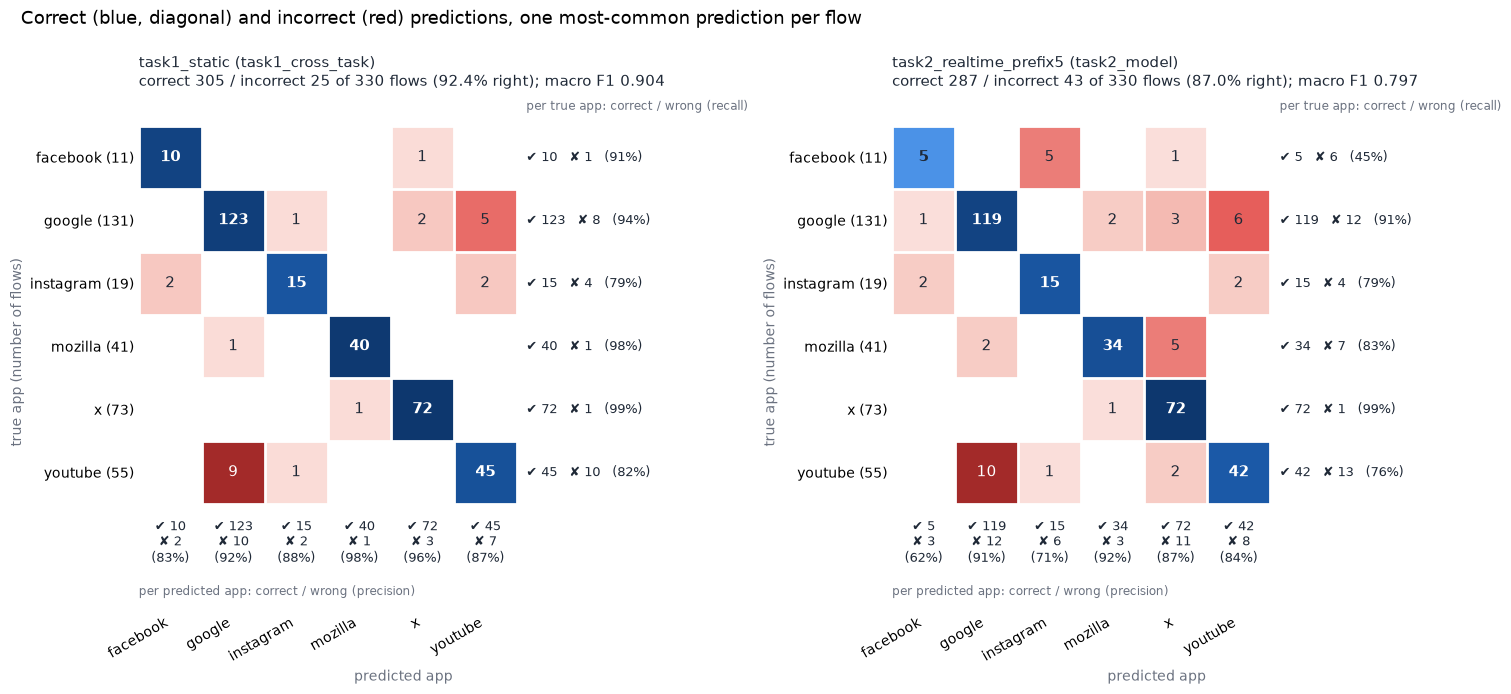

In [14]:
# demo: confusion matrices of the production models, from their champion cross-validation runs,
# with the number of correct (blue, diagonal) and incorrect (red, off-diagonal) predictions
import json

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

APPS = ["facebook", "google", "instagram", "mozilla", "x", "youtube"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
REDS = LinearSegmentedColormap.from_list("reds", ["#fdf0ee", "#f4b4ab", "#e34948", "#a32a29"])
INK, MUTED = "#1f2937", "#6b7280"
champions = json.loads((ROOT / "results" / "champions.json").read_text())


def per_flow(task):
    """Each labelled flow's most common out-of-fold prediction in the task's champion run."""
    run = champions[task]["run_id"]
    oof = pd.read_csv(ROOT / "results" / run / task / "oof.csv")
    v = oof.groupby("flow_id").agg(y_true=("y_true", "first"), y_pred=("y_pred", lambda s: s.value_counts().idxmax()))
    return run, v


fig, axes = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True)
for ax, task in zip(axes, ["task1_static", "task2_realtime_prefix5"]):
    run, v = per_flow(task)
    cm = confusion_matrix(v.y_true, v.y_pred, labels=APPS)
    n = len(APPS)
    diag = np.eye(n, dtype=bool)
    row_share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(np.ma.masked_where(~diag, row_share), cmap=BLUES, vmin=0, vmax=1)
    off = np.ma.masked_where(diag | (cm == 0), cm)
    ax.imshow(off, cmap=REDS, vmin=0, vmax=max(1, cm[~diag].max()))
    for i in range(n):
        for j in range(n):
            if cm[i, j]:
                dark = (diag[i, j] and row_share[i, j] > 0.55) or (not diag[i, j] and cm[i, j] > 0.6 * cm[~diag].max())
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=11,
                        fontweight="bold" if diag[i, j] else "normal", color="white" if dark else INK)
    # margins: per true app (right) and per predicted app (bottom)
    for i, a in enumerate(APPS):
        ok, wrong = cm[i, i], cm[i].sum() - cm[i, i]
        ax.text(n - 0.35, i, f"✔ {ok}   ✘ {wrong}   ({ok / max(cm[i].sum(), 1):.0%})", va="center", fontsize=9.5, color=INK)
    for j, a in enumerate(APPS):
        ok, wrong = cm[j, j], cm[:, j].sum() - cm[j, j]
        ax.text(j, n - 0.25, f"✔ {ok}\n✘ {wrong}\n({ok / max(cm[:, j].sum(), 1):.0%})", ha="center", va="top", fontsize=9, color=INK)
    ax.text(n - 0.35, -0.75, "per true app: correct / wrong (recall)", fontsize=8.5, color=MUTED)
    ax.text(-0.5, n + 0.95, "per predicted app: correct / wrong (precision)", fontsize=8.5, color=MUTED)
    ax.set_xticks(np.arange(-0.5, n), minor=True)
    ax.set_yticks(np.arange(-0.5, n), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(n), APPS, rotation=30, ha="right")
    ax.set_yticks(range(n), [f"{a} ({c})" for a, c in zip(APPS, cm.sum(axis=1))])
    ax.set_xlim(-0.5, n + 1.9)
    ax.set_ylim(n + 1.2, -1.0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel("predicted app", color=MUTED)
    ax.set_ylabel("true app (number of flows)", color=MUTED)
    total_ok = int(np.trace(cm))
    ax.set_title(f"{task} ({TASK_MODELS[task].__name__})\ncorrect {total_ok} / incorrect {cm.sum() - total_ok} of {cm.sum()} flows "
                 f"({total_ok / cm.sum():.1%} right); macro F1 {macro_f1(v.y_true, v.y_pred):.3f}", loc="left", fontsize=11, color=INK)
fig.suptitle("Correct (blue, diagonal) and incorrect (red) predictions, one most-common prediction per flow",
             x=0.01, ha="left", fontsize=13)
plt.show()

The same results as numbers: precision and recall per app, and the most common mistakes.

In [15]:
# demo: per-app precision and recall, and the most common mistakes (true app -> predicted app)
from sklearn.metrics import classification_report

for task in ["task1_static", "task2_realtime_prefix5"]:
    run, v = per_flow(task)
    print(f"{task} (champion run {run})")
    print(classification_report(v.y_true, v.y_pred, labels=APPS, digits=3, zero_division=0))
    wrong = v[v.y_true != v.y_pred].groupby(["y_true", "y_pred"]).size().sort_values(ascending=False)
    print(f"{len(v) - (v.y_true == v.y_pred).sum()} of {len(v)} flows wrong; most common mistakes:")
    print(wrong.head(6).rename("flows").to_string(), "\n")

task1_static (champion run 20261012T154049Z_100_production_check_s2026)
              precision    recall  f1-score   support

    facebook      0.833     0.909     0.870        11
      google      0.925     0.939     0.932       131
   instagram      0.882     0.789     0.833        19
     mozilla      0.976     0.976     0.976        41
           x      0.960     0.986     0.973        73
     youtube      0.865     0.818     0.841        55

    accuracy                          0.924       330
   macro avg      0.907     0.903     0.904       330
weighted avg      0.924     0.924     0.924       330

25 of 330 flows wrong; most common mistakes:
y_true     y_pred  
youtube    google      9
google     youtube     5
           x           2
instagram  facebook    2
           youtube     2
facebook   x           1 

task2_realtime_prefix5 (champion run 20260930T173836Z_014_fi_same_nocw)
              precision    recall  f1-score   support

    facebook      0.625     0.455     0.5